# Healthy spectra — cross-experiment reproducibility exploration

**Input:** `../data/healthy_pre_leak.csv` when run from `notebooks/` (also supports project-root execution).

**Primary question:** At a fixed **probe**, **elapsed second**, and **Reynolds operating point**, how much does each frequency amplitude vary **between different experiment files**? We compare `f160` with `f10000` and all other frequency columns independently; comparing the magnitude of *different* frequencies is a separate, secondary descriptive question.

**Important:** Matching exact seconds and Reynolds may yield few repeated observations. This notebook reports coverage and supports an explicitly labeled **Reynolds tolerance** rather than silently treating unmatched observations as equivalent. It never fabricates repetitions or pools different probes.

In [26]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths from either project root or notebooks/
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot locate project root (directory containing data/).")
INPUT = ROOT / "data" / "healthy_pre_leak.csv"
OUT = ROOT / "results" / "healthy_cross_experiment_eda"
OUT.mkdir(parents=True, exist_ok=True)
if not INPUT.exists():
    raise FileNotFoundError(f"Missing {INPUT}. Run src/extract_healthy.py first.")
print("Input:", INPUT, "\nOutputs:", OUT)

# CONFIGURATION
RE_TOLERANCE = 0.0     # 0: exact Reynolds matching; >0: allow nearest value within tolerance
MIN_EXPERIMENTS = 2   # Require >=2 distinct files for cross-experiment spread
TOP_N = 20
EXAMPLE_PROBE = "DS"
EXAMPLE_SECOND = 10.0
EXAMPLE_REYNOLDS = 10.0
EXAMPLE_FREQUENCIES = ["f160", "f10000"]


Input: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/data/healthy_pre_leak.csv 
Outputs: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/healthy_cross_experiment_eda


## 1. Load and validate

`file_name` identifies an experiment and `probe` its sensor. `Date-Time` is elapsed seconds per file; `Date-Time-orig` is preserved for auditing. `Reynolds` is obtained from the stripped `ǀReynolds` column.

In [30]:
cols= ['file_name'	,'probe','Date-Time',	'Reynolds'	]
import numpy as np

def filter_reynolds(df, values=[12.5, 25, 50, 100, 150],
                    strict=True, tolerance=0.1):
    if strict:
        return df[df["Reynolds_level"].isin(values)].copy()

    mask = np.isclose(
        df["Reynolds_level"].to_numpy()[:, None],
        values,
        atol=tolerance,
        rtol=0
    ).any(axis=1)

    return df[mask].copy()
df = pd.read_csv(INPUT, low_memory=False)

filter_reynolds(df, values=[12.5, 25, 50, 100, 150],
                    strict=False, tolerance=0.1)[['Reynolds_level','probe']].value_counts().reset_index().sort_values('Reynolds_level')

,Reynolds_level,probe,count
4,0.0,DS,307
5,0.0,UUS,307
6,12.5,DS,36
7,12.5,UUS,36
15,12.5,US,9
14,12.5,DDS,9
17,25.0,US,5
8,25.0,DS,25
9,25.0,UUS,25
16,25.0,DDS,5


In [42]:
def filter_reynolds(df, values=[12.5, 25, 50, 100, 150],
                    strict=True, tolerance=0.1):
    if strict:
        return df[df["Reynolds_level"].isin(values)].copy()

    mask = np.isclose(
        df["Reynolds_level"].to_numpy()[:, None],
        values,
        atol=tolerance,
        rtol=0
    ).any(axis=1)

    return df[mask].copy()

df = pd.read_csv(INPUT, low_memory=False)
df = df[df["Reynolds_level"] != 0].copy()
df.columns = df.columns.astype(str).str.strip()
print("Rows:", len(df), "Columns:", len(df.columns))
print("Columns:", df.columns.tolist())

# Normalize unexpected remnants of sensor-prefix separators (both broken bar and pipe).
rename = {c: re.split(r"[ǀ|]", c)[-1].strip() for c in df.columns if "ǀ" in c or "|" in c}
if rename:
    df = df.rename(columns=rename)
required = ["probe", "file_name", "Date-Time", "Reynolds_level"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns {missing}. Available: {df.columns.tolist()}")
freqs = sorted([c for c in df.columns if re.fullmatch(r"f\d+(?:\.\d+)?", c)], key=lambda x: float(x[1:]))
if not freqs:
    raise ValueError("No frequency columns such as f160 or f10000 found")
print(f"Found {len(freqs)} frequency channels:", freqs)
for c in ["Date-Time", "Reynolds_level", *freqs]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["probe"] = df["probe"].astype(str).str.strip().str.upper()
df["file_name"] = df["file_name"].astype(str).str.strip()
df = df.dropna(subset=["Date-Time", "Reynolds_level", "probe", "file_name"]).copy()
if "Leak Event" in df.columns:
    print("Nonzero leak flags in extracted file:", int((pd.to_numeric(df["Leak Event"], errors="coerce").fillna(0) != 0).sum()))
print("Files per probe:")
display(df.groupby("probe").agg(files=("file_name", "nunique"), rows=("file_name", "size")))


Rows: 59400 Columns: 35
Columns: ['file_name', 'probe', 'Date-Time-orig', 'Date-Time', 'Reynolds_level', 'Reynolds', 'f100', 'f1000', 'f10000', 'f125', 'f1250', 'f160', 'f1600', 'f200', 'f2000', 'f25', 'f250', 'f2500', 'f3100', 'f315', 'f31_5', 'f40', 'f400', 'f4000', 'f50', 'f500', 'f5000', 'f63', 'f630', 'f6300', 'f80', 'f800', 'f8000', 'Leak Event', 'Reynolds_Level']
Found 26 frequency channels: ['f25', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
Nonzero leak flags in extracted file: 0
Files per probe:


,files,rows
probe,,
DDS,1,3000
DS,5,14400
US,1,3000
UUS,5,14400


## 2. Match observations across experiments

First match on **probe + exact elapsed second**. If `RE_TOLERANCE = 0`, also require identical Reynolds values. With positive tolerance, observations at the same second are matched to the **median Reynolds at that second** only when their Reynolds difference is at most the tolerance. This does not align different elapsed seconds or correct for different flow trajectories. We require one observation per file in each group.

In [43]:
# Check duplicate probe/file/second rows before grouping.
dups = df.duplicated(["probe", "file_name", "Date-Time"], keep=False)
print("Duplicate file/probe/second rows:", int(dups.sum()))
if dups.any():
    display(df.loc[dups, ["probe", "file_name", "Date-Time", "Reynolds_level"]].head(12))
    raise ValueError("Duplicate file/probe/second keys; inspect source before comparing experiments.")

work = df.copy()
if RE_TOLERANCE == 0:
    work["re_match"] = work["Reynolds_level"]
else:
    if RE_TOLERANCE < 0:
        raise ValueError("RE_TOLERANCE must be nonnegative")
    reference = work.groupby(["probe", "Date-Time"])["Reynolds_level"].transform("median")
    work = work.loc[(work["Reynolds_level"] - reference).abs() <= RE_TOLERANCE].copy()
    work["re_match"] = reference.loc[work.index]

keys = ["probe", "Date-Time", "re_match"]
coverage = (work.groupby(keys, dropna=False)
            .agg(n_experiments=("file_name", "nunique"),
                 reynolds_min=("Reynolds_level", "min"), reynolds_max=("Reynolds_level", "max"))
            .reset_index())
print("Total matched operating-point groups:", len(coverage))
print(f"Groups with >= {MIN_EXPERIMENTS} distinct experiments:", int((coverage.n_experiments >= MIN_EXPERIMENTS).sum()))
display(coverage.groupby("probe").agg(total_groups=("n_experiments", "size"),
            replicated_groups=("n_experiments", lambda x: int((x >= MIN_EXPERIMENTS).sum())),
            max_experiments=("n_experiments", "max")))

# Cross-experiment comparison is meaningful only on replicated groups.
valid_keys = coverage.loc[coverage.n_experiments >= MIN_EXPERIMENTS, keys]
matched = work.merge(valid_keys, on=keys, how="inner")
if matched.empty:
    print("NO MATCHED GROUPS. Inspect Reynolds matching and elapsed-second alignment. ")
    print("Try a small, physically justified RE_TOLERANCE and rerun this section onward.")


Duplicate file/probe/second rows: 0
Total matched operating-point groups: 15000
Groups with >= 2 distinct experiments: 6000


,total_groups,replicated_groups,max_experiments
probe,,,
DDS,3000,0,1
DS,4500,3000,5
US,3000,0,1
UUS,4500,3000,5


## 3. Cross-experiment dispersion for each probe × second × Reynolds × frequency

For each matched operating point, calculate across-file **mean, standard deviation, min/max range, interquartile range**, and **coefficient of variation** (`std / abs(mean)`, undefined near zero). A large spread is *not automatically anomalous*: sensor calibration, flow conditions, alignment and the number of experiments must be considered. Rank by standard deviation and range, and retain the number of experiments.

In [44]:

# 3. Cross-experiment dispersion by probe × Reynolds × second × frequency

group_keys = ["probe", "Reynolds_level", "Date-Time"]
spread_keys = group_keys + ["frequency"]

if matched.empty:
    spread = pd.DataFrame(columns=spread_keys + [
        "n_experiments", "mean", "std", "min", "max",
        "q25", "q75", "range", "iqr", "cv"
    ])
else:
    long = matched.melt(
        id_vars=group_keys + ["file_name"],
        value_vars=freqs,
        var_name="frequency",
        value_name="amplitude"
    ).dropna(subset=["amplitude"])

    grp = long.groupby(spread_keys, observed=True)["amplitude"]

    spread = grp.agg(
        n_experiments="count",
        mean="mean",
        std="std",
        min="min",
        max="max",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    ).reset_index()

    spread = spread[
        spread["n_experiments"] >= MIN_EXPERIMENTS
    ].copy()

    spread["range"] = spread["max"] - spread["min"]
    spread["iqr"] = spread["q75"] - spread["q25"]

    spread["cv"] = (
        spread["std"] /
        spread["mean"].abs().where(spread["mean"].abs() > 1e-8)
    )

    spread = spread.sort_values(
        ["probe", "Reynolds_level", "std"],
        ascending=[True, True, False]
    )

spread.to_csv(
    OUT / "per_operating_point_frequency_spread.csv",
    index=False
)

print("Comparable groups:", len(spread))

# Top N frequencies/seconds separately for each probe and Reynolds level
top_spread = (
    spread.groupby(["probe", "Reynolds_level"], group_keys=False)
    .head(TOP_N)
    .reset_index(drop=True)
)

display(top_spread[[
    "probe", "Reynolds_level", "Date-Time",
    "frequency", "n_experiments",
    "mean", "std", "range", "iqr", "cv"
]])


Comparable groups: 156000


,probe,Reynolds_level,Date-Time,frequency,n_experiments,mean,std,range,iqr,cv
0,DS,12.5,119.0,f630,3,34.192674,20.970960,36.686826,18.343413,0.613317
1,DS,12.5,120.0,f630,3,31.337315,18.166195,31.485401,15.742701,0.579699
2,DS,12.5,119.0,f160,3,37.810481,17.541253,30.589690,15.294845,0.463926
3,DS,12.5,119.0,f80,3,40.818742,16.221846,29.547548,14.773774,0.397412
4,DS,12.5,121.0,f80,3,40.313706,14.547477,26.925152,13.462576,0.360857
...,...,...,...,...,...,...,...,...,...,...
195,UUS,150.0,2776.0,f80,5,39.087987,8.496385,18.191726,12.387940,0.217366
196,UUS,150.0,2435.0,f5000,4,10.010377,8.417423,17.281604,12.067086,0.840870
197,UUS,150.0,2985.0,f80,5,38.184126,8.365771,18.189429,14.982603,0.219090
198,UUS,150.0,2405.0,f80,4,37.274876,8.302741,19.677456,6.456707,0.222744


In [46]:
# Mean amplitude for each run at a fixed operating condition
run_means = (
    long.groupby(
        ["probe", "Reynolds_level", "file_name", "frequency"],
        observed=True
    )["amplitude"]
    .mean()
    .reset_index(name="run_mean")
)

# Between-run variability
between_run = (
    run_means.groupby(
        ["probe", "Reynolds_level", "frequency"],
        observed=True
    )
    .agg(
        n_runs=("file_name", "nunique"),
        mean_amplitude=("run_mean", "mean"),
        between_run_std=("run_mean", "std")
    )
    .reset_index()
)
display(run_means)
display(between_run)

,probe,Reynolds_level,file_name,frequency,run_mean
0,DS,12.5,DS1211_1,f100,31.633261
1,DS,12.5,DS1211_1,f1000,25.320361
2,DS,12.5,DS1211_1,f10000,4.819963
3,DS,12.5,DS1211_1,f125,35.329645
4,DS,12.5,DS1211_1,f1250,22.812877
...,...,...,...,...,...
1243,UUS,150.0,UUS1213_2,f630,29.481637
1244,UUS,150.0,UUS1213_2,f6300,2.670295
1245,UUS,150.0,UUS1213_2,f80,44.467158
1246,UUS,150.0,UUS1213_2,f800,19.562840


,probe,Reynolds_level,frequency,n_runs,mean_amplitude,between_run_std
0,DS,12.5,f100,4,29.899080,1.258471
1,DS,12.5,f1000,4,17.227000,5.408183
2,DS,12.5,f10000,4,4.787915,0.021862
3,DS,12.5,f125,4,31.795924,2.406679
4,DS,12.5,f1250,4,14.351007,5.650138
...,...,...,...,...,...,...
255,UUS,150.0,f630,5,29.719578,0.720076
256,UUS,150.0,f6300,5,3.405958,0.855347
257,UUS,150.0,f80,5,39.448631,5.761506
258,UUS,150.0,f800,5,19.834774,0.682860


In [49]:
run_stats = (
    long.groupby(
        ["probe", "Reynolds_level", "file_name", "frequency"],
        observed=True
    )
    .agg(
        n_samples=("amplitude", "size"),
        run_mean=("amplitude", "mean"),
        within_run_std=("amplitude", "std")
    )
    .reset_index()
)
display(run_stats)

,probe,Reynolds_level,file_name,frequency,n_samples,run_mean,within_run_std
0,DS,12.5,DS1211_1,f100,600,31.633261,1.866651
1,DS,12.5,DS1211_1,f1000,600,25.320361,0.864997
2,DS,12.5,DS1211_1,f10000,600,4.819963,0.250467
3,DS,12.5,DS1211_1,f125,600,35.329645,2.076401
4,DS,12.5,DS1211_1,f1250,600,22.812877,0.709597
...,...,...,...,...,...,...,...
1243,UUS,150.0,UUS1213_2,f630,600,29.481637,1.035137
1244,UUS,150.0,UUS1213_2,f6300,600,2.670295,1.793359
1245,UUS,150.0,UUS1213_2,f80,600,44.467158,2.125174
1246,UUS,150.0,UUS1213_2,f800,600,19.562840,0.685305


## 4. Which frequencies vary most across experiments?

Aggregate the per-operating-point dispersion **separately by probe and frequency**. Median standard deviation is less dominated by a few outliers than the mean. The `n_points` column prevents interpreting a frequency with only one matched operating point as a robust result.

,probe,frequency,n_points,median_std,mean_std,median_range,p90_std
10,DS,f250,3000,9.132787,8.842547,19.301471,10.226930
6,DS,f1600,3000,6.401149,6.503786,13.761644,7.283460
4,DS,f1250,3000,5.598860,5.649951,12.098240,6.291079
1,DS,f1000,3000,5.082176,5.167578,11.141847,5.905446
8,DS,f2000,3000,4.490844,4.661642,9.762335,5.383038
24,DS,f800,3000,4.214502,4.285897,9.443494,4.928930
21,DS,f630,3000,4.087254,4.161733,9.079178,4.931542
23,DS,f80,3000,3.578325,3.660964,8.358290,5.361544
49,UUS,f80,3000,4.282735,4.090945,9.589940,6.713894
29,UUS,f125,3000,3.779054,3.892012,8.601004,5.264663


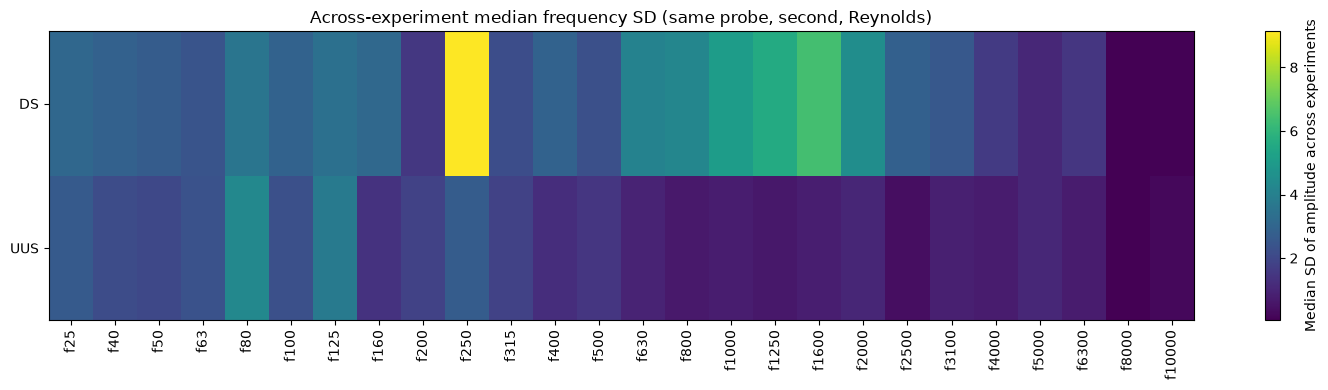

In [50]:
if not spread.empty:
    summary = (spread.groupby(["probe", "frequency"], observed=True)
               .agg(n_points=("std", "size"), median_std=("std", "median"),
                    mean_std=("std", "mean"), median_range=("range", "median"),
                    p90_std=("std", lambda x: x.quantile(.9)))
               .reset_index().sort_values(["probe", "median_std"], ascending=[True, False]))
    summary.to_csv(OUT / "probe_frequency_variability_summary.csv", index=False)
    display(summary.groupby("probe", group_keys=False).head(8))
    pivot = summary.pivot(index="probe", columns="frequency", values="median_std").reindex(columns=freqs)
    fig, ax = plt.subplots(figsize=(15, 4))
    im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="viridis")
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=90)
    ax.set_title("Across-experiment median frequency SD (same probe, second, Reynolds)")
    fig.colorbar(im, ax=ax, label="Median SD of amplitude across experiments")
    fig.tight_layout(); fig.savefig(OUT / "frequency_variability_heatmap.png", dpi=170); plt.show()
else:
    summary = pd.DataFrame()
    print("No matched groups: no valid frequency variability ranking.")


## 5. Inspect one example operating point (e.g. DS, second 10, Reynolds 10)

This plot displays the actual values of each frequency across experiment files at the selected operating point. When there is no exact match, it explains the missing coverage instead of substituting a different Reynolds value silently.

Reynolds levels after filtering:
[np.float64(12.5), np.float64(25.0), np.float64(50.0), np.float64(100.0), np.float64(150.0)]


,probe,Reynolds_level,frequency,n_points,median_std,mean_std,median_range,p90_std
10,DS,12.5,f250,600,9.824534,9.834358,20.249750,10.686181
6,DS,12.5,f1600,600,7.037088,7.121613,13.594938,7.974859
4,DS,12.5,f1250,600,5.999398,6.081246,11.710585,6.768626
1,DS,12.5,f1000,600,5.690105,5.771531,11.173462,6.547505
8,DS,12.5,f2000,600,4.656440,4.748902,9.369963,5.241229
...,...,...,...,...,...,...,...,...
254,UUS,150.0,f63,600,3.324826,3.359943,7.873230,4.891809
244,UUS,150.0,f250,600,2.566991,2.590095,5.861267,3.534822
243,UUS,150.0,f25,600,2.548055,2.669481,6.067979,3.987962
248,UUS,150.0,f40,600,2.109754,2.186244,5.043715,3.216681


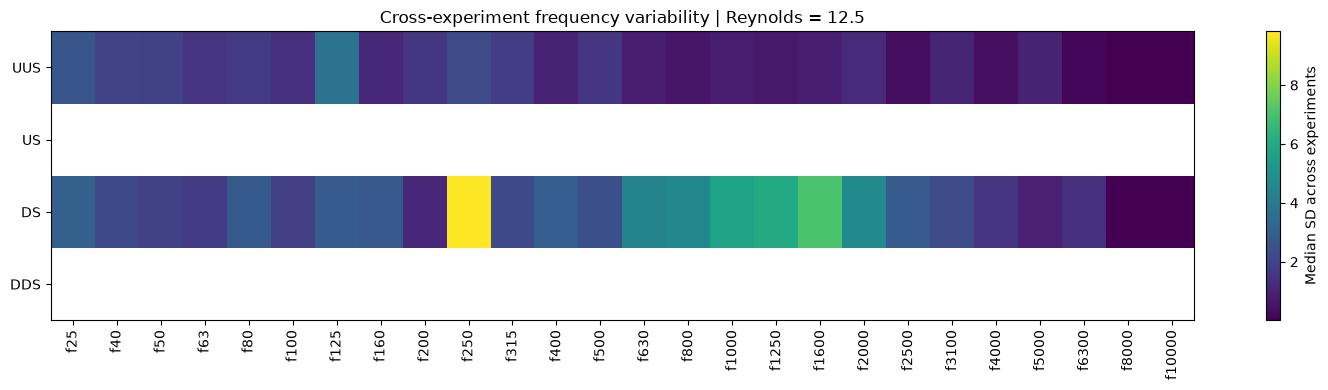

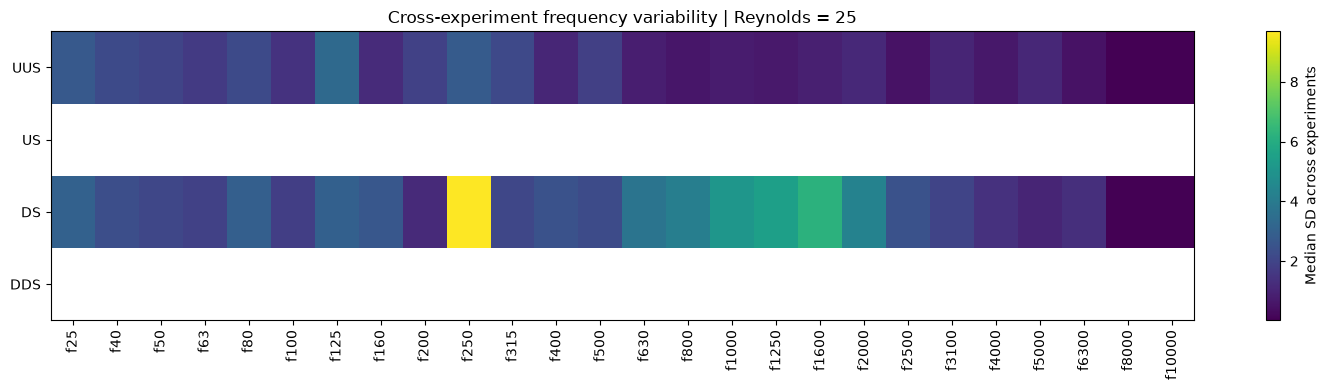

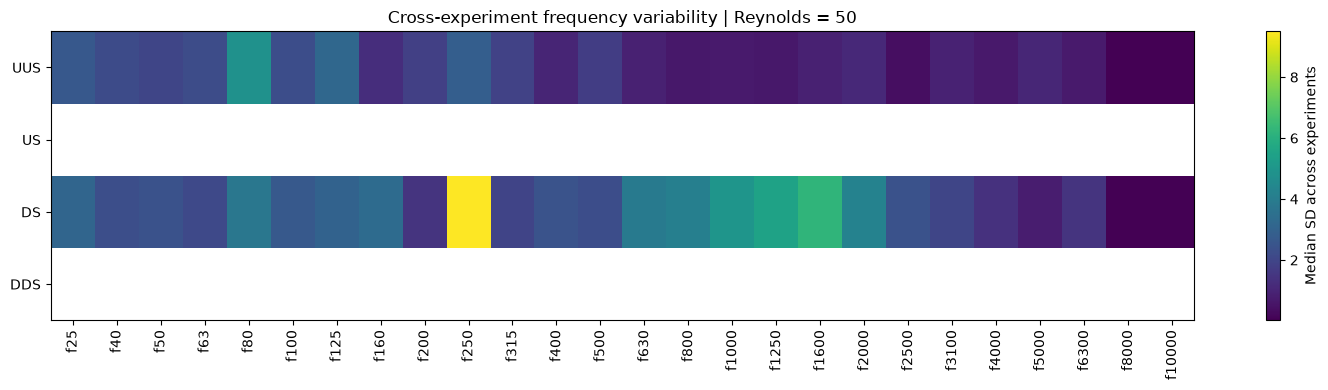

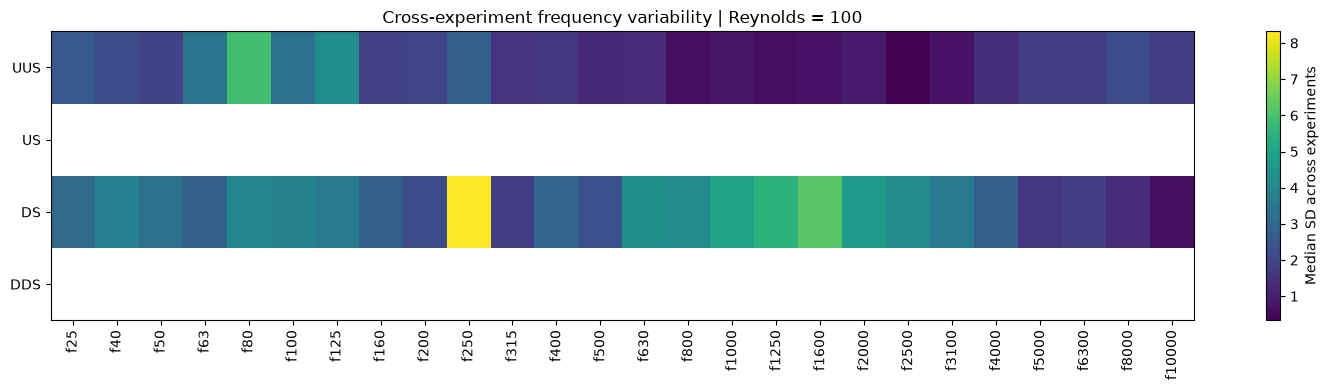

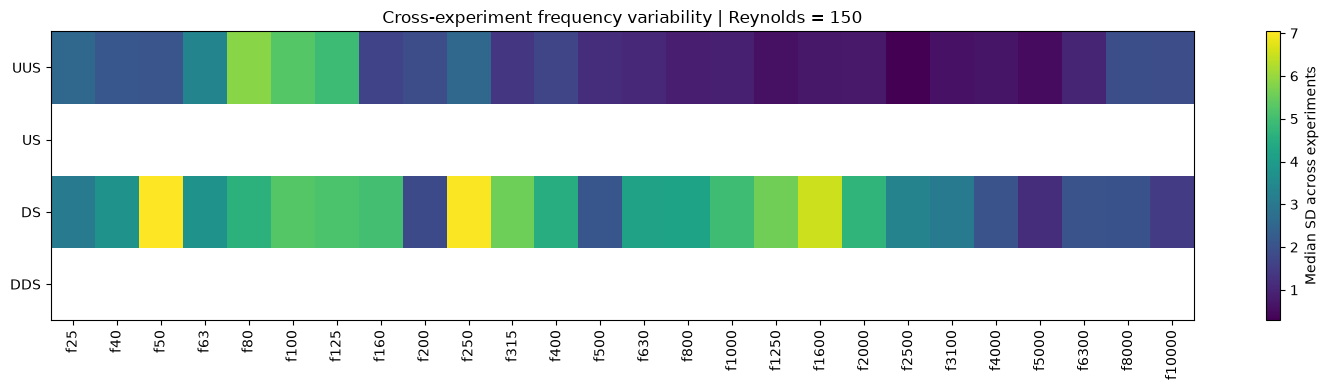

In [51]:

# 4. Frequency variability summary by probe × Reynolds level
REYNOLDS_LEVELS = [12.5, 25, 50, 100, 150]

spread = spread[
    spread["Reynolds_level"].isin(REYNOLDS_LEVELS)
].copy()

print("Reynolds levels after filtering:")
print(sorted(spread["Reynolds_level"].unique()))
if not spread.empty:
    summary = (
        spread.groupby(
            ["probe", "Reynolds_level", "frequency"],
            observed=True
        )
        .agg(
            n_points=("std", "size"),
            median_std=("std", "median"),
            mean_std=("std", "mean"),
            median_range=("range", "median"),
            p90_std=("std", lambda x: x.quantile(0.9))
        )
        .reset_index()
        .sort_values(
            ["probe", "Reynolds_level", "median_std"],
            ascending=[True, True, False]
        )
    )

    summary.to_csv(
        OUT / "probe_reynolds_frequency_variability_summary.csv",
        index=False
    )

    # Top 8 frequencies for each probe and Reynolds level
    top_summary = (
        summary.groupby(
            ["probe", "Reynolds_level"],
            group_keys=False
        )
        .head(8)
    )

    display(top_summary[[
        "probe", "Reynolds_level", "frequency",
        "n_points", "median_std", "mean_std",
        "median_range", "p90_std"
    ]])
    # One heatmap per Reynolds level
    #for re_level in sorted(summary["Reynolds_level"].dropna().unique()):
    for re_level in [12.5, 25, 50, 100, 150]:
        subset = summary[
            summary["Reynolds_level"] == re_level
        ]

        pivot = (
            subset.pivot(
                index="probe",
                columns="frequency",
                values="median_std"
            )
            .reindex(
                index=["UUS", "US", "DS", "DDS"],
                columns=freqs
            )
        )

        fig, ax = plt.subplots(figsize=(15, 4))

        im = ax.imshow(
            pivot.to_numpy(),
            aspect="auto",
            cmap="viridis"
        )

        ax.set_yticks(
            range(len(pivot.index)),
            pivot.index
        )

        ax.set_xticks(
            range(len(pivot.columns)),
            pivot.columns,
            rotation=90
        )

        ax.set_title(
            f"Cross-experiment frequency variability | Reynolds = {re_level:g}"
        )

        fig.colorbar(
            im,
            ax=ax,
            label="Median SD across experiments"
        )

        fig.tight_layout()

        fig.savefig(
            OUT / f"frequency_variability_Re_{re_level:g}.png",
            dpi=170
        )

        plt.show()

else:
    summary = pd.DataFrame()
    print("No matched groups: no valid frequency variability ranking.")


In [52]:
RE = 12.5

for name, data in [
    ("Original df", df),
    ("Matched", matched),
    ("Spread", spread),
    ("Summary", summary)
]:
    print(f"\n{name} — Reynolds {RE}")

    re_col = (
        "Reynolds_level"
        if "Reynolds_level" in data.columns
        else "Reynolds"
    )

    subset = data[
        np.isclose(
            pd.to_numeric(data[re_col], errors="coerce"),
            RE,
            atol=0.1,
            rtol=0
        )
    ]

    print("Rows by probe:")
    print(
        subset.groupby("probe")
        .size()
        .reindex(["UUS", "US", "DS", "DDS"], fill_value=0)
    )

    if "file_name" in subset.columns:
        print("Distinct experiments:")
        print(
            subset.groupby("probe")["file_name"]
            .nunique()
            .reindex(["UUS", "US", "DS", "DDS"], fill_value=0)
        )


Original df — Reynolds 12.5
Rows by probe:
probe
UUS    2400
US      600
DS     2400
DDS     600
dtype: int64
Distinct experiments:
probe
UUS    4
US     1
DS     4
DDS    1
Name: file_name, dtype: int64

Matched — Reynolds 12.5
Rows by probe:
probe
UUS    2100
US        0
DS     2100
DDS       0
dtype: int64
Distinct experiments:
probe
UUS    4
US     0
DS     4
DDS    0
Name: file_name, dtype: int64

Spread — Reynolds 12.5
Rows by probe:
probe
UUS    15600
US         0
DS     15600
DDS        0
dtype: int64

Summary — Reynolds 12.5
Rows by probe:
probe
UUS    26
US      0
DS     26
DDS     0
dtype: int64


## 6. Example frequency distributions across files

At each matched operating point, the plot below shows the **distribution of the selected frequency's amplitude across experiment files**, not the distribution across unrelated frequencies. With only 2–5 files, use individual points rather than relying on a smooth density estimate.

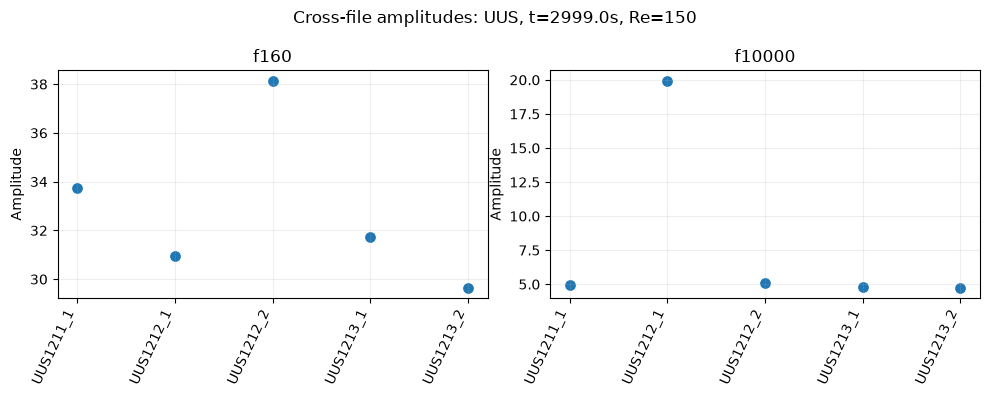

In [53]:
if not spread.empty:
    best = coverage.loc[coverage.n_experiments >= MIN_EXPERIMENTS].sort_values("n_experiments", ascending=False).iloc[0]
    selection = matched.loc[(matched.probe == best["probe"]) &
        (matched["Date-Time"] == best["Date-Time"]) &
        (matched.re_match == best["re_match"])].sort_values("file_name")
    selected = [f for f in EXAMPLE_FREQUENCIES if f in freqs]
    if not selected:
        selected = freqs[:2]
    fig, axes = plt.subplots(1, len(selected), figsize=(5*len(selected), 4), squeeze=False)
    for ax, f in zip(axes[0], selected):
        ax.scatter(range(len(selection)), selection[f], s=45)
        ax.set_xticks(range(len(selection)), selection.file_name, rotation=65, ha="right")
        ax.set_ylabel("Amplitude"); ax.set_title(f)
        ax.grid(alpha=.2)
    fig.suptitle(f"Cross-file amplitudes: {best['probe']}, t={best['Date-Time']}s, Re={best['re_match']:.5g}")
    fig.tight_layout(); fig.savefig(OUT / "example_frequency_values_by_experiment.png", dpi=170); plt.show()
else:
    print("No replicated groups to plot.")


## 7. Secondary check: spread *across frequencies within one spectrum*

This answers a **different** question: for one file/probe/second/Re observation, how wide is the range of the 27 amplitudes? Large differences between `f160` and `f10000` may be entirely normal because they are different spectral bands. Do **not** use this as evidence of cross-experiment inconsistency.

In [54]:
df["within_spectrum_range"] = df[freqs].max(axis=1) - df[freqs].min(axis=1)
df["within_spectrum_std"] = df[freqs].std(axis=1)
within = df[["file_name", "probe", "Date-Time", "Reynolds_level", "within_spectrum_range", "within_spectrum_std"]].sort_values("within_spectrum_range", ascending=False)
within.to_csv(OUT / "within_spectrum_spread_descriptive_only.csv", index=False)
display(within.head(15))
print("Do not interpret this ranking as cross-experiment reproducibility.")


,file_name,probe,Date-Time,Reynolds_level,within_spectrum_range,within_spectrum_std
50110,UUS1212_1,UUS,1210.0,50.0,57.626664,15.507513
50108,UUS1212_1,UUS,1208.0,50.0,56.668669,15.116765
59040,UUS1213_2,UUS,840.0,25.0,55.775500,14.985373
28440,DS1213_2,DS,840.0,25.0,55.419117,14.830699
52550,UUS1212_2,UUS,650.0,25.0,54.789013,14.853107
15419,DS1211_1,DS,119.0,12.5,54.512000,18.445773
30086,DS1213_2,DS,2486.0,150.0,54.506606,16.363535
52834,UUS1212_2,UUS,934.0,25.0,54.493133,14.565703
49848,UUS1212_1,UUS,948.0,25.0,54.473880,14.611158
53105,UUS1212_2,UUS,1205.0,50.0,54.334754,14.454148


Do not interpret this ranking as cross-experiment reproducibility.


## 8. Interpretation and data-quality limitations

- The **primary output** is `per_operating_point_frequency_spread.csv`, with one row per probe × elapsed second × Reynolds × frequency, when at least two different experiment files match.
- `probe_frequency_variability_summary.csv` and the heatmap identify frequency/probe channels with relatively large **between-experiment** variability at matched operating points.
- **Small sample caveat:** With 2 files, standard deviation and IQR are unstable; inspect raw file values and `n_experiments`.
- Matching Reynolds and elapsed time does **not** control for temperature, calibration, prior flow history, or other unmeasured conditions.
- If no groups match, examine `coverage` and choose a justified Reynolds tolerance or change the comparison design. Do not infer that there is no variation.
- For Stage 1 dataset design, large variation at the same input Reynolds history suggests omitted predictors or irreducible uncertainty, but single-time matching alone cannot establish this: the preceding 40-step Reynolds histories must also be compared.
- Avoid selecting training/test data using information from held-out test runs; reserve separate experiments for validation.
